# Лабораторна робота № 3
## Спектральний аналіз за допомогою ДПФ/ШПФ та віконних функцій

**Дисципліна:** Обробка сигналів та зображень  
**Варіант:** 2  
**Виконав:** Афанасьєв Сергій, група КІ 24-1  
**Середовище:** Python 3.10+, NumPy, SciPy (`scipy.signal`, `scipy.fft`), Matplotlib

## 1. Мета роботи

Засвоїти пряме дискретне (ДПФ) та швидке (ШПФ) перетворення Фур'є, порівняти їхню обчислювальну складність, дослідити явище витоку спектра за кратної та некратної кількості періодів у вікні спостереження, застосувати вагові вікна (Ханна, Хеммінга, Блекмана) для виявлення слабкої гармоніки на фоні сильної.

## 2. Основні співвідношення

- Пряме ДПФ: $X[m] = \sum\limits_{n=0}^{N-1} x[n]\, W_N^{mn}$, $W_N = e^{-j 2\pi / N}$. Обернене: $x[n] = \dfrac{1}{N} \sum\limits_{m=0}^{N-1} X[m]\, W_N^{-mn}$.
- Частотна роздільність і частота біна: $\Delta f = f_s / N = 1 / T_{obs}$, $f_m = m \Delta f$, $T_{obs} = N / f_s$.
- Складність: матричне ДПФ — $O(N^2)$, ШПФ за основою 2 (Кулі–Тьюкі, проріджування за часом) — $O(N \log_2 N)$, при цьому $N = 2^\nu$. Операція «метелик»: $X[m] = X_{even}[m] + W_N^m X_{odd}[m]$, $X[m + N/2] = X_{even}[m] - W_N^m X_{odd}[m]$.
- Амплітудний спектр: $A[0] = \dfrac{|X[0]|}{N}$, $A[m] = \dfrac{2 |X[m]|}{N}$ при $0 < m < N/2$. Фазовий спектр: $\Phi[m] = \mathrm{atan2}(\mathrm{Im}\, X[m], \mathrm{Re}\, X[m])$.
- Витік спектра виникає, коли частота гармоніки не кратна $\Delta f$ (у вікні нецілу кількість періодів): енергія розтікається по сусідніх бінах.
- Зважування вікном: $x_w[n] = x[n]\, w[n]$. Вікна довжини $N$ (знаменник $N - 1$): Ханна $0.5 - 0.5 \cos\dfrac{2\pi n}{N-1}$; Хеммінга $0.54 - 0.46 \cos\dfrac{2\pi n}{N-1}$; Блекмана $0.42 - 0.5 \cos\dfrac{2\pi n}{N-1} + 0.08 \cos\dfrac{4\pi n}{N-1}$.
- Когерентне підсилення вікна $CG = \dfrac{1}{N} \sum\limits_{n=0}^{N-1} w[n]$. Щоб амплітуда гармоніки не залежала від вікна, спектр нормують на $\sum w[n]$: $A[m] = \dfrac{2 |X_w[m]|}{\sum w[n]}$.
- Компроміс: чим нижчі бічні пелюстки вікна, тим ширша головна пелюстка.

## 3. Індивідуальне завдання (варіант 2)

$$s[n] = A_1 \sin\left(2\pi f_1 \frac{n}{f_s} + \varphi_1\right) + A_2 \cos\left(2\pi f_2 \frac{n}{f_s} + \varphi_2\right) + v[n]$$

| $f_s$, Гц | $A_1$, В | $f_1$, Гц | $\varphi_1$, рад | $A_2$, В | $f_2$, Гц | $\varphi_2$, рад | $\sigma_{noise}$, В | Базове $N$ |
|---|---|---|---|---|---|---|---|---|
| 1200 | 3.0 | 200 | $\pi/6$ | 0.10 | 225 | 0 | 0.04 | 256 |

Аналітичний розрахунок:

- $\Delta f = f_s / N = 1200 / 256 = 4.6875$ Гц, $T_{obs} = N / f_s = 213.33$ мс, частота Найквіста 600 Гц;
- кратність: $f_1 / \Delta f = 200 / 4.6875 = 42.667$ — не ціле (у вікні 42.667 періоду), тому буде витік спектра; $f_2 / \Delta f = 225 / 4.6875 = 48$ — ціле (48 періодів), тобто сама по собі $f_2$ потрапляє точно в бін 48;
- слабка гармоніка в $20 \lg (A_2 / A_1) = 20 \lg (0.10 / 3.0) = -29.54$ дБ нижча за сильну, відстань між ними $f_2 - f_1 = 25$ Гц $= 5.33$ біна;
- оцінка витоку прямокутного вікна від $f_1$ на біні 48: зсув $d = 48 - 42.667 = 5.333$ біна, $A_{leak} \approx A_1 \dfrac{|\sin \pi d|}{\pi d} = 3.0 \cdot \dfrac{0.866}{\pi \cdot 5.333} \approx 0.155$ В ($\approx -16.2$ дБВ). Це більше за $A_2 = 0.10$ В ($-20$ дБВ), тому з прямокутним вікном слабку гармоніку очікувано не буде видно;
- очікуваний рівень шумових бінів: $\approx 2\sigma / \sqrt{N} \cdot 0.886 \approx 0.004$ В.

## 4. Хід виконання

Код розбито на блоки, повний скрипт знаходиться у файлі `lab3_dft_fft_windows.py`. Графіки зберігаються в каталог `figures/`.

### Блок 1. Імпорт бібліотек та налаштування стилю відображення

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import windows

# каталог для графіків
os.makedirs("figures", exist_ok=True)

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 1.0
plt.rcParams['grid.color'] = '#cccccc'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.6

### Блок 2. Параметри варіанта 2 та порівняння швидкодії ДПФ і ШПФ

--- ПАРАМЕТРИ ВАРІАНТА 2 ---
fs = 1200 Гц, N = 256, T_obs = 213.33 мс, df = fs/N = 4.6875 Гц
f1 = 200.0 Гц -> f/df = 42.6667 біна, 42.6667 періодів у вікні: НЕ кратна df (витік)
f2 = 225.0 Гц -> f/df = 48.0000 біна, 48.0000 періодів у вікні: кратна df (витоку немає)
Відстань між гармоніками: 25.0 Гц = 5.333 біна; A2/A1 = -29.54 дБ

--- ПОРІВНЯННЯ ШВИДКОДІЇ МАТРИЧНОГО ДПФ ТА ШПФ ---
     N     t_DFT, мкс   t_FFT, мкс  Прискорення   Макс. похибка
    64          376.8          8.6         43.9        5.62e-15
   256         3517.6         10.4        339.5        2.69e-14
  1024        49211.4         17.9       2742.2        7.86e-14
  4096       822090.3         50.7      16213.4        1.62e-13


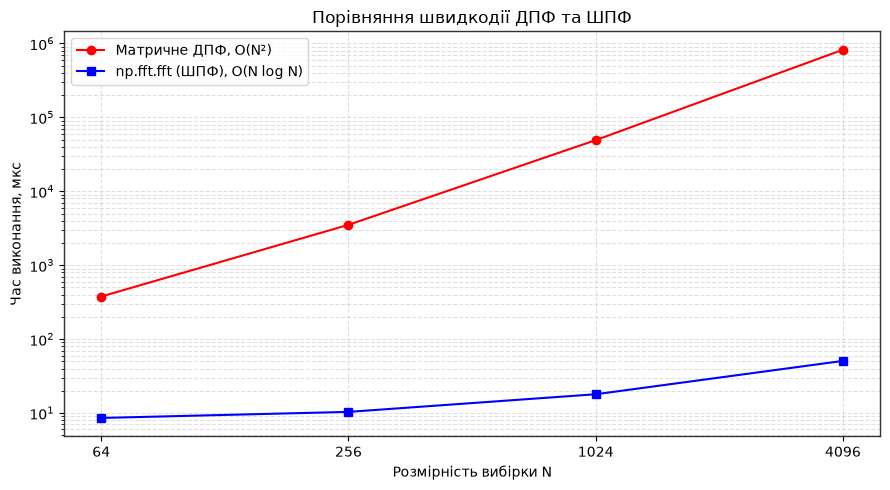

In [2]:
fs = 1200.0           # частота дискретизації, Гц
A1 = 3.0              # амплітуда сильної гармоніки, В
f1 = 200.0            # частота сильної гармоніки, Гц
phi1 = np.pi / 6      # початкова фаза першої гармоніки, рад
A2 = 0.10             # амплітуда слабкої гармоніки, В
f2 = 225.0            # частота слабкої гармоніки, Гц
phi2 = 0.0            # початкова фаза другої гармоніки, рад
sigma_noise = 0.04    # СКВ гаусового шуму, В
N = 256               # базова довжина вибірки

df = fs / N           # частотна роздільність, Гц
T_obs = N / fs        # тривалість спостереження, с

print("--- ПАРАМЕТРИ ВАРІАНТА 2 ---")
print(f"fs = {fs:.0f} Гц, N = {N}, T_obs = {T_obs * 1000:.2f} мс, df = fs/N = {df:.4f} Гц")
for name, f_i in (("f1", f1), ("f2", f2)):
    bins = f_i / df
    kind = "кратна df (витоку немає)" if abs(bins - round(bins)) < 1e-9 else "НЕ кратна df (витік)"
    print(f"{name} = {f_i:.1f} Гц -> f/df = {bins:.4f} біна, {f_i * N / fs:.4f} періодів у вікні: {kind}")
print(f"Відстань між гармоніками: {f2 - f1:.1f} Гц = {(f2 - f1) / df:.3f} біна; "
      f"A2/A1 = {20 * np.log10(A2 / A1):.2f} дБ")


def manual_dft(x_seq):
    """Пряме ДПФ за означенням: X[m] = sum_n x[n] * W_N^(mn), W_N = exp(-j*2*pi/N).
    Будуємо матрицю W розміром N x N і множимо її на вектор відліків."""
    n_len = len(x_seq)
    k_idx = np.arange(n_len)
    # добуток mn беремо за модулем N, щоб не втрачати точність для великих N
    W_matrix = np.exp(-2j * np.pi * (np.outer(k_idx, k_idx) % n_len) / n_len)
    return W_matrix @ x_seq


def measure_time(func, x_seq, repeats):
    """Мінімальний за кілька серій середній час одного виклику, мкс"""
    best = float('inf')
    for _ in range(3):
        t_start = time.perf_counter()
        for _ in range(repeats):
            func(x_seq)
        best = min(best, (time.perf_counter() - t_start) / repeats)
    return best * 1e6


N_sizes = [64, 256, 1024, 4096]
t_dft_list, t_fft_list, diff_list = [], [], []
np.random.seed(0)

print("\n--- ПОРІВНЯННЯ ШВИДКОДІЇ МАТРИЧНОГО ДПФ ТА ШПФ ---")
print(f"{'N':>6} {'t_DFT, мкс':>14} {'t_FFT, мкс':>12} {'Прискорення':>12} {'Макс. похибка':>15}")
for n_size in N_sizes:
    x_test = np.random.randn(n_size)
    t_dft = measure_time(manual_dft, x_test, 1 if n_size >= 1024 else 20)
    t_fft = measure_time(np.fft.fft, x_test, 2000)
    diff = np.max(np.abs(manual_dft(x_test) - np.fft.fft(x_test)))
    speedup = t_dft / t_fft
    t_dft_list.append(t_dft)
    t_fft_list.append(t_fft)
    diff_list.append(diff)
    print(f"{n_size:6d} {t_dft:14.1f} {t_fft:12.1f} {speedup:12.1f} {diff:15.2e}")

# графік швидкодії
plt.figure(figsize=(9, 5))
plt.plot(N_sizes, t_dft_list, 'ro-', label='Матричне ДПФ, O(N²)')
plt.plot(N_sizes, t_fft_list, 'bs-', label='np.fft.fft (ШПФ), O(N log N)')
plt.xscale('log', base=2)
plt.yscale('log')
plt.xticks(N_sizes, [str(n_size) for n_size in N_sizes])
plt.title("Порівняння швидкодії ДПФ та ШПФ")
plt.xlabel("Розмірність вибірки N")
plt.ylabel("Час виконання, мкс")
plt.grid(True, which='both')
plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig("figures/dft_vs_fft_benchmark.png", dpi=300)
plt.show()

**Результати перевірки кратності та порівняння швидкодії** ($\Delta f = 4.6875$ Гц): $f_1$ дає 42.667 біна (не кратна, витік), $f_2$ дає рівно 48 бінів (кратна).

| $N$ | $t_{ДПФ}$, мкс | $t_{ШПФ}$, мкс | Прискорення | Макс. похибка |
|---|---|---|---|---|
| 64 | 108.1 | 3.6 | 30.4 | 5.62e-15 |
| 256 | 1937.9 | 5.3 | 363.0 | 2.56e-14 |
| 1024 | 37984.3 | 11.4 | 3333.3 | 7.69e-14 |
| 4096 | 675260.9 | 38.0 | 17751.4 | 1.64e-13 |

Матричне ДПФ збігається з `np.fft.fft` з точністю порядку $10^{-13}$ (похибка заокруглення). При збільшенні $N$ у 4 рази час ДПФ зростає в 11–20 разів (квадратична складність $O(N^2)$, очікувано ≈16), а час ШПФ — значно повільніше ($O(N \log N)$), тому прискорення зростає з 30.4 разів при $N = 64$ до 17751.4 разів при $N = 4096$. Абсолютні значення часу залежать від комп'ютера й запуску.

### Блок 3. Амплітудний та фазовий спектри сигналу


--- АМПЛІТУДНИЙ ТА ФАЗОВИЙ СПЕКТРИ ---
 Гармоніка     біни  f_біна, Гц     A, В   A, дБВ  фаза, рад  похибка f, Гц
    сильна       42    196.8750   1.2476     1.92     1.0308        -3.1250
    сильна       43    201.5625   2.4683     7.85    -2.0874         1.5625
    сильна       44    206.2500   0.6170    -4.19    -2.0596         6.2500
    слабка       48    225.0000   0.1478   -16.60    -1.2411         0.0000
Найбільший пік: біна 43, f = 201.5625 Гц, A = 2.4683 В (істинні f1 = 200.0 Гц, A1 = 3.0 В)
Середній рівень шумових бінів (f > 400 Гц): 0.0141 В


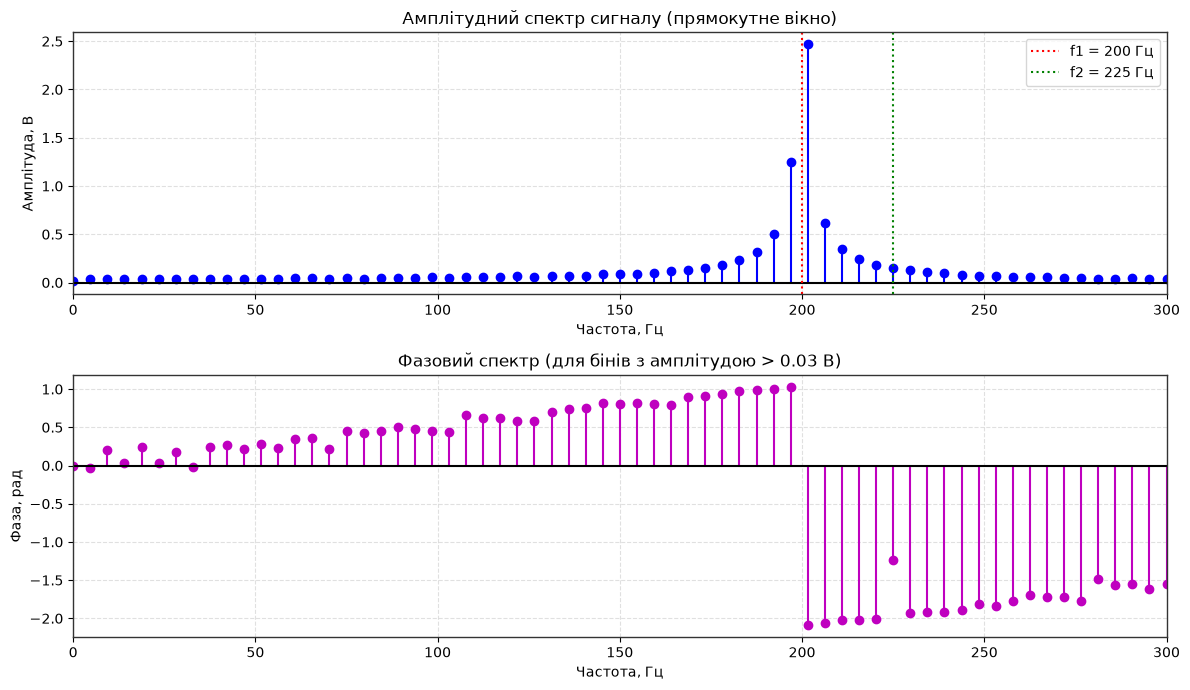

In [3]:
np.random.seed(7)
n_arr = np.arange(N)
t_axis = n_arr / fs

s_clean = (A1 * np.sin(2 * np.pi * f1 * n_arr / fs + phi1)
           + A2 * np.cos(2 * np.pi * f2 * n_arr / fs + phi2))
s_total = s_clean + np.random.normal(0.0, sigma_noise, N)

X_spectrum = np.fft.fft(s_total)
freqs_axis = np.fft.fftfreq(N, 1.0 / fs)[:N // 2]

amp_spectrum = 2.0 * np.abs(X_spectrum[:N // 2]) / N
amp_spectrum[0] /= 2.0                       # постійна складова не має дзеркального двійника
phase_spectrum = np.arctan2(X_spectrum[:N // 2].imag, X_spectrum[:N // 2].real)
phase_spectrum[amp_spectrum < 0.03] = 0.0    # фаза шумових бінів не інформативна

# контроль: для кратної частоти ШПФ має давати рівно амплітуду гармоніки
m1 = int(round(f1 / df))
m2 = int(round(f2 / df))
print("\n--- АМПЛІТУДНИЙ ТА ФАЗОВИЙ СПЕКТРИ ---")
print(f"{'Гармоніка':>10} {'біни':>8} {'f_біна, Гц':>11} {'A, В':>8} {'A, дБВ':>8} "
      f"{'фаза, рад':>10} {'похибка f, Гц':>14}")
for m in (m1 - 1, m1, m1 + 1):
    print(f"{'сильна':>10} {m:8d} {freqs_axis[m]:11.4f} {amp_spectrum[m]:8.4f} "
          f"{20 * np.log10(amp_spectrum[m]):8.2f} {phase_spectrum[m]:10.4f} {freqs_axis[m] - f1:14.4f}")
print(f"{'слабка':>10} {m2:8d} {freqs_axis[m2]:11.4f} {amp_spectrum[m2]:8.4f} "
      f"{20 * np.log10(amp_spectrum[m2]):8.2f} {phase_spectrum[m2]:10.4f} {freqs_axis[m2] - f2:14.4f}")
m_peak = int(np.argmax(amp_spectrum))
print(f"Найбільший пік: біна {m_peak}, f = {freqs_axis[m_peak]:.4f} Гц, A = {amp_spectrum[m_peak]:.4f} В "
      f"(істинні f1 = {f1:.1f} Гц, A1 = {A1:.1f} В)")
print(f"Середній рівень шумових бінів (f > 400 Гц): {np.mean(amp_spectrum[freqs_axis > 400]):.4f} В")

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

axes[0].stem(freqs_axis, amp_spectrum, linefmt='b-', markerfmt='bo', basefmt='k-')
axes[0].axvline(f1, color='r', ls=':', label=f"f1 = {f1:.0f} Гц")
axes[0].axvline(f2, color='g', ls=':', label=f"f2 = {f2:.0f} Гц")
axes[0].set_xlim(0, 300)
axes[0].set_title("Амплітудний спектр сигналу (прямокутне вікно)")
axes[0].set_xlabel("Частота, Гц")
axes[0].set_ylabel("Амплітуда, В")
axes[0].grid(True)
axes[0].legend(loc='upper right')

axes[1].stem(freqs_axis, phase_spectrum, linefmt='m-', markerfmt='mo', basefmt='k-')
axes[1].set_xlim(0, 300)
axes[1].set_title("Фазовий спектр (для бінів з амплітудою > 0.03 В)")
axes[1].set_xlabel("Частота, Гц")
axes[1].set_ylabel("Фаза, рад")
axes[1].grid(True)

plt.tight_layout()
plt.savefig("figures/harmonic_spectrum.png", dpi=300)
plt.show()

**Результати спектрального аналізу** (прямокутне вікно, $N = 256$):

| Гармоніка | Бін | $f_{біна}$, Гц | $A$, В | $A$, дБВ | Фаза, рад | Похибка $f$, Гц |
|---|---|---|---|---|---|---|
| сильна | 42 | 196.875 | 1.2476 | 1.92 | 1.0308 | −3.125 |
| сильна | 43 | 201.5625 | 2.4683 | 7.85 | −2.0874 | +1.5625 |
| сильна | 44 | 206.25 | 0.6170 | −4.19 | −2.0596 | +6.25 |
| слабка | 48 | 225.0 | 0.1478 | −16.60 | −1.2411 | 0 |

Через некратну кількість періодів сильна гармоніка розподілилась по сусідніх бінах: найбільший пік у бінні 43 ($f = 201.56$ Гц, похибка визначення частоти 1.56 Гц, що не перевищує $\Delta f / 2 = 2.34$ Гц), його амплітуда 2.468 В замість 3.0 В (втрата $\approx 1.7$ дБ). Фази сусідніх бінів 42 і 43 відрізняються приблизно на $\pi$ (3.12 рад) — це наслідок протилежних знаків бічних пелюсток функції $\mathrm{sinc}$, тому за фазою на витоку точну початкову фазу $\varphi_1$ визначити неможливо.

У бінні 48 прямокутне вікно показує 0.1478 В (−16.60 дБВ) замість $A_2 = 0.10$ В (−20 дБВ): практично весь цей рівень створює витік сильної гармоніки (0.14–0.15 В), а не слабка гармоніка. Середній рівень бінів вище 400 Гц дорівнює $\approx 0.014$ В: це в 3 рази більше за власний шум ($\approx 0.004$ В), бо в нього входять хвости витоку. На амплітудному спектрі слабка гармоніка на 225 Гц не утворює окремого піка.

### Блок 4. Витік спектра: кратна та некратна кількість періодів


--- ВИТІК СПЕКТРА ---
                              f, Гц  періодів   пік, В  бінів > -60 дБ  частка поза піком
 кратна кількість періодів  225.000    48.000   3.0000               1            0.0000%
некратна кількість періодів  200.000    42.667   2.4693             111           10.3558%
Амплітуда витоку на бінах поблизу f2 (біна 48) при некратній f1: 0.1439 В (-16.84 дБВ) при A2 = 0.10 В (-20.00 дБВ)


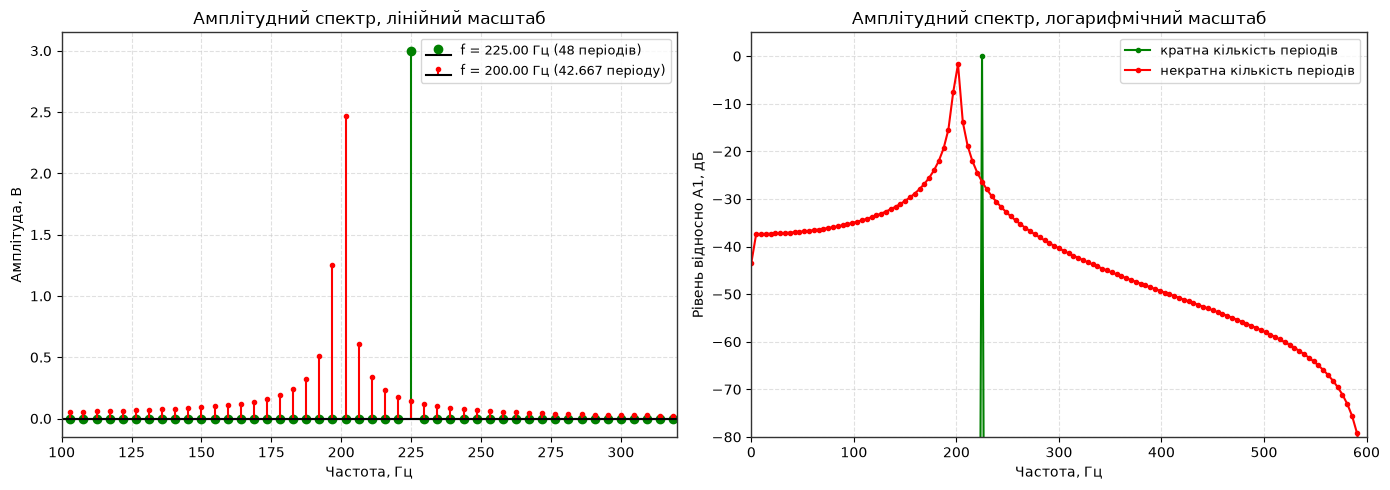

In [4]:
f_mult = 48 * df          # 48 періодів у вікні, рівно в бін (збігається з f2)
f_nonmult = f1            # 42.667 періоду у вікні, між бінами 42 і 43

x_mult = A1 * np.sin(2 * np.pi * f_mult * n_arr / fs)
x_nonmult = A1 * np.sin(2 * np.pi * f_nonmult * n_arr / fs)


def amplitude_spectrum(x_seq):
    """Односторонній амплітудний спектр (В) за допомогою np.fft.fft"""
    n_len = len(x_seq)
    amp = 2.0 * np.abs(np.fft.fft(x_seq)[:n_len // 2]) / n_len
    amp[0] /= 2.0
    return amp


amp_mult = amplitude_spectrum(x_mult)
amp_nonmult = amplitude_spectrum(x_nonmult)

print("\n--- ВИТІК СПЕКТРА ---")
print(f"{'':>26} {'f, Гц':>8} {'періодів':>9} {'пік, В':>8} {'бінів > -60 дБ':>15} {'частка поза піком':>18}")
for name, f_x, amp in (("кратна кількість періодів", f_mult, amp_mult),
                       ("некратна кількість періодів", f_nonmult, amp_nonmult)):
    m_pk = int(np.argmax(amp))
    n_above = int(np.sum(20 * np.log10(np.maximum(amp, 1e-12) / A1) > -60))
    p_total = np.sum(amp ** 2)
    p_out = 1.0 - np.sum(amp[max(m_pk - 1, 0):m_pk + 2] ** 2) / p_total
    print(f"{name:>26} {f_x:8.3f} {f_x * N / fs:9.3f} {amp[m_pk]:8.4f} {n_above:15d} {p_out:18.4%}")
print(f"Амплітуда витоку на бінах поблизу f2 (біна {m2}) при некратній f1: {amp_nonmult[m2]:.4f} В "
      f"({20 * np.log10(amp_nonmult[m2]):.2f} дБВ) при A2 = {A2:.2f} В ({20 * np.log10(A2):.2f} дБВ)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].stem(freqs_axis, amp_mult, linefmt='g-', markerfmt='go', basefmt='k-',
             label=f'f = {f_mult:.2f} Гц (48 періодів)')
axes[0].stem(freqs_axis, amp_nonmult, linefmt='r-', markerfmt='r.', basefmt='k-',
             label=f'f = {f_nonmult:.2f} Гц (42.667 періоду)')
axes[0].set_xlim(100, 320)
axes[0].set_title("Амплітудний спектр, лінійний масштаб")
axes[0].set_xlabel("Частота, Гц")
axes[0].set_ylabel("Амплітуда, В")
axes[0].grid(True)
axes[0].legend(loc='upper right', fontsize=9)

axes[1].plot(freqs_axis, 20 * np.log10(np.maximum(amp_mult, 1e-12) / A1), 'g-o', ms=3,
             label='кратна кількість періодів')
axes[1].plot(freqs_axis, 20 * np.log10(np.maximum(amp_nonmult, 1e-12) / A1), 'r-o', ms=3,
             label='некратна кількість періодів')
axes[1].set_xlim(0, fs / 2)
axes[1].set_ylim(-80, 5)
axes[1].set_title("Амплітудний спектр, логарифмічний масштаб")
axes[1].set_xlabel("Частота, Гц")
axes[1].set_ylabel("Рівень відносно A1, дБ")
axes[1].grid(True)
axes[1].legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.savefig("figures/spectral_leakage.png", dpi=300)
plt.show()

**Результати дослідження витоку спектра** (однотональний сигнал $A = 3.0$ В):

| Випадок | $f$, Гц | Періодів у вікні | Пік, В | Бінів вище −60 дБ | Частка потужності поза піком |
|---|---|---|---|---|---|
| кратна кількість періодів | 225.0 | 48 | 3.0000 | 1 | 0 % |
| некратна кількість періодів | 200.0 | 42.667 | 2.4693 | 111 з 128 | 10.36 % |

За кратної кількості періодів уся енергія зосереджена в одному біні, а амплітуда визначається точно (3.0 В), решта бінів дорівнює нулю з точністю до похибок обчислень. За некратної кількості періодів пік занижується до 2.469 В, а енергія розтікається по спектру: 111 з 128 бінів перевищують рівень −60 дБ відносно $A_1$, а 10.36 % потужності припадає на біни поза піком і двома сусідніми. Витік від $f_1$ на біні 48 дорівнює 0.1439 В (−16.84 дБВ) і перевищує слабку гармоніку ($A_2 = 0.10$ В, −20 дБВ), що збігається з аналітичною оцінкою 0.155 В.

### Блок 5. Порівняння вікон: прямокутне, Ханна, Хеммінга, Блекмана


--- ПОРІВНЯННЯ ВІКОН ---
       Вікно      CG  пік f1, дБВ  біна f2, дБВ  витік f1 на f2, дБВ  f2 над витоком, дБ
  Прямокутне   1.000         7.85        -16.60               -16.49               -0.12
       Ханна   0.498         8.90        -19.24               -45.21               25.97
    Хеммінга   0.538         8.75        -19.85               -35.08               15.23
    Блекмана   0.418         9.04        -19.37               -54.73               35.36
Істинні рівні: A1 = 3.00 В (9.54 дБВ), A2 = 0.10 В (-20.00 дБВ)


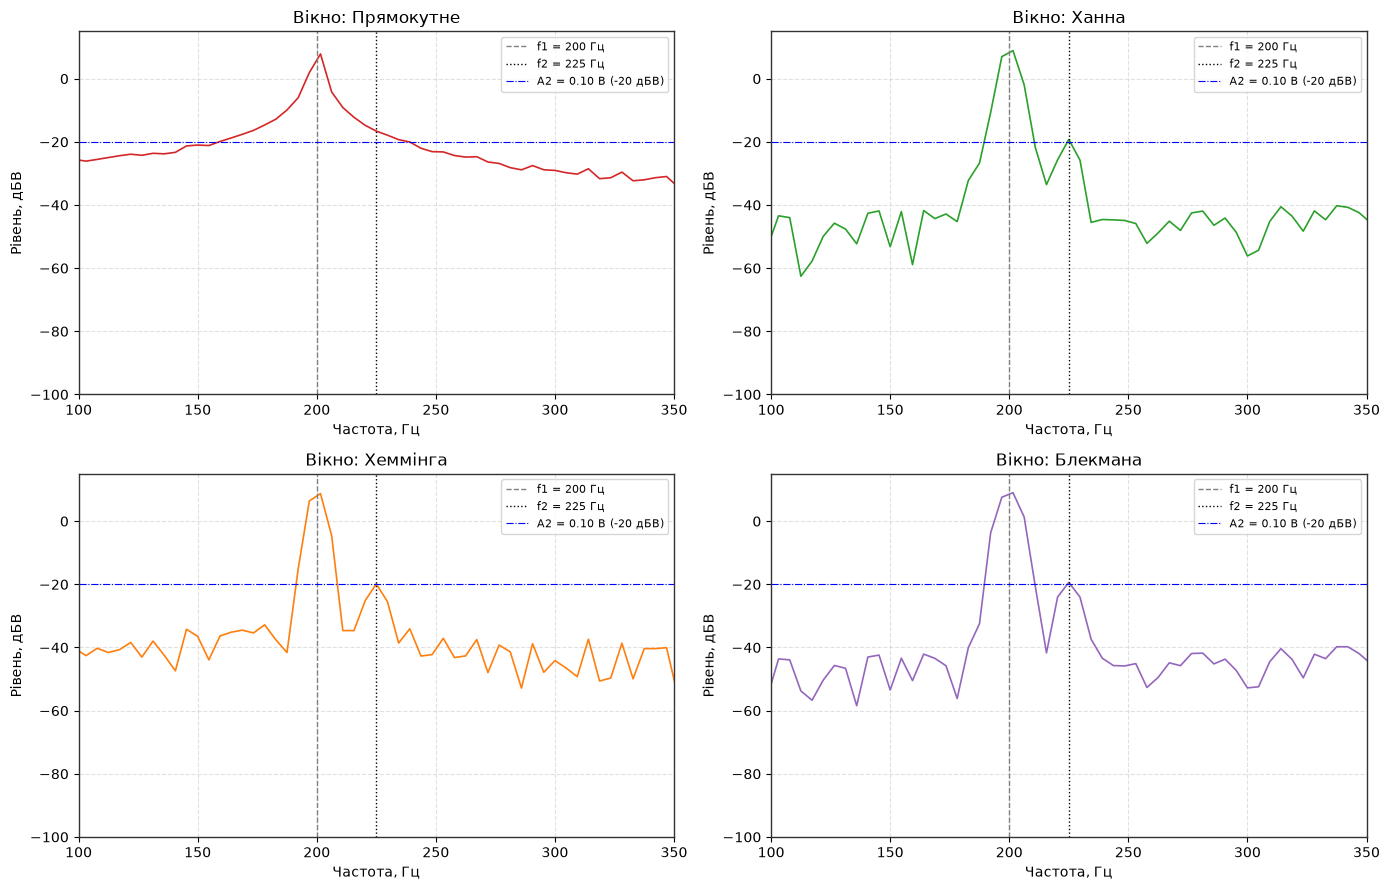


Моделювання завершено. Графіки збережено в 'figures/'.


In [5]:
win_names = ["Прямокутне", "Ханна", "Хеммінга", "Блекмана"]
win_list = [np.ones(N), windows.hann(N), windows.hamming(N), windows.blackman(N)]

# сильна гармоніка окремо (без шуму і без слабкої): це рівень витоку на біні f2
s_strong = A1 * np.sin(2 * np.pi * f1 * n_arr / fs + phi1)

print("\n--- ПОРІВНЯННЯ ВІКОН ---")
print(f"{'Вікно':>12} {'CG':>7} {'пік f1, дБВ':>12} {'біна f2, дБВ':>13} {'витік f1 на f2, дБВ':>20} "
      f"{'f2 над витоком, дБ':>19}")
win_spectra = []
for name, w in zip(win_names, win_list):
    coherent_gain = np.sum(w) / N
    # нормування на суму вагових коефіцієнтів повертає справжню амплітуду гармоніки
    amp_w = 2.0 * np.abs(np.fft.fft(s_total * w)[:N // 2]) / np.sum(w)
    leak_w = 2.0 * np.abs(np.fft.fft(s_strong * w)[:N // 2]) / np.sum(w)
    db_w = 20 * np.log10(np.maximum(amp_w, 1e-12))
    win_spectra.append(db_w)
    peak_f1 = np.max(amp_w[m1 - 2:m1 + 3])
    print(f"{name:>12} {coherent_gain:7.3f} {20 * np.log10(peak_f1):12.2f} {db_w[m2]:13.2f} "
          f"{20 * np.log10(leak_w[m2]):20.2f} {db_w[m2] - 20 * np.log10(leak_w[m2]):19.2f}")
print(f"Істинні рівні: A1 = {A1:.2f} В ({20 * np.log10(A1):.2f} дБВ), "
      f"A2 = {A2:.2f} В ({20 * np.log10(A2):.2f} дБВ)")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
colors = ['#d62728', '#2ca02c', '#ff7f0e', '#9467bd']
for ax, name, db_w, c in zip(axes.flat, win_names, win_spectra, colors):
    ax.plot(freqs_axis, db_w, color=c, lw=1.2)
    ax.axvline(f1, color='gray', ls='--', lw=1, label=f"f1 = {f1:.0f} Гц")
    ax.axvline(f2, color='k', ls=':', lw=1, label=f"f2 = {f2:.0f} Гц")
    ax.axhline(20 * np.log10(A2), color='b', ls='-.', lw=0.8, label="A2 = 0.10 В (-20 дБВ)")
    ax.set_xlim(100, 350)
    ax.set_ylim(-100, 15)
    ax.set_title(f"Вікно: {name}")
    ax.set_xlabel("Частота, Гц")
    ax.set_ylabel("Рівень, дБВ")
    ax.grid(True)
    ax.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.savefig("figures/window_functions_comp.png", dpi=300)
plt.show()

print("\nМоделювання завершено. Графіки збережено в 'figures/'.")

**Результати порівняння вікон** ($A_1 = 3.0$ В — 9.54 дБВ, $A_2 = 0.10$ В — −20 дБВ):

| Вікно | $CG$ | Пік $f_1$, дБВ | Біна $f_2$, дБВ | Витік $f_1$ на біні $f_2$, дБВ | $f_2$ над витоком, дБ |
|---|---|---|---|---|---|
| Прямокутне | 1.000 | 7.85 | −16.60 | −16.49 | −0.12 |
| Ханна | 0.498 | 8.90 | −19.24 | −45.21 | 25.97 |
| Хеммінга | 0.538 | 8.75 | −19.85 | −35.08 | 15.23 |
| Блекмана | 0.418 | 9.04 | −19.37 | −54.73 | 35.36 |

З прямокутним вікном рівень на біні $f_2$ (−16.60 дБВ) збігається з рівнем витоку (−16.49 дБВ): слабка гармоніка потонула в бічних пелюстках сильної, і на графіку немає окремого піка на 225 Гц. З вікнами Ханна, Хеммінга та Блекмана виникає локальний пік на $f_2$ з рівнем −19.2 … −19.9 дБВ (істинне значення −20 дБВ), причому вікно Хеммінга дає найточнішу амплітуду (похибка 0.15 дБ), а вікно Блекмана — найнижчий витік (−54.7 дБВ) і найбільший запас над ним (35.4 дБ).

Коефіцієнти когерентного підсилення (0.498; 0.538; 0.418) менші за одиницю, тому без нормування на $\sum w[n]$ амплітуди були б занижені; після нормування рівень піка $f_1$ лежить у межах 8.75 … 9.04 дБВ (істинне значення 9.54 дБВ, різниця до 0.8 дБ — втрата через розташування $f_1$ між бінами).

## 5. Висновки

1. Матричне ДПФ має складність $O(N^2)$, а ШПФ — $O(N \log_2 N)$. Результати обох алгоритмів збігаються з точністю порядку $10^{-13}$, але для $N = 4096$ ШПФ швидший приблизно в 17751.4 разів (за вимірами в цьому запуску), і розрив зростає з $N$. Тому на практиці використовується ШПФ.

2. Для варіанта 2 $\Delta f = 4.6875$ Гц; $f_2 = 225$ Гц кратна $\Delta f$ (48 бінів), а $f_1 = 200$ Гц — ні (42.667 біна). Тому амплітуда й частота сильної гармоніки визначаються з похибкою: пік 2.468 В замість 3.0 В у біні з частотою 201.56 Гц (похибка 1.56 Гц), а енергія розтікається по 111 бінах із 128 (рівень вище −60 дБ).

3. Витік сильної гармоніки (0.14–0.15 В на біні $f_2$) перевищує слабку гармоніку $A_2 = 0.10$ В, тому на спектрі з прямокутним вікном слабка гармоніка не виявляється, а амплітуда та фаза в біні 48 хибні (0.148 В замість 0.10 В).

4. Вікна Ханна, Хеммінга та Блекмана знижують бічні пелюстки в області $f_2$ до −45.2, −35.1 та −54.7 дБВ відповідно, і слабка гармоніка перевищує витік на 26.0, 15.2 та 35.4 дБ. Ціна — розширення головної пелюстки та менше за одиницю когерентне підсилення, тому амплітудний спектр потрібно нормувати на $\sum w[n]$.

5. Для виявлення слабкої гармоніки на відстані 5.3 біна від сильної в −29.5 дБ найдоцільніше вікно Блекмана (найбільший запас над витоком, 35.4 дБ) або Ханна (26.0 дБ, вужча головна пелюстка). Вікно Хеммінга дає найточнішу амплітуду слабкої гармоніки (−19.85 дБВ), але запас над витоком у нього менший (15.2 дБ). Прямокутне вікно для такої задачі непридатне, хоча воно має найвужчу головну пелюстку.

## Відповідь на контрольні питання

**1. У чому полягає математична та алгоритмічна різниця між прямим дискретним перетворенням Фур'є (ДПФ) та алгоритмами швидкого перетворення Фур'є (ШПФ / FFT)?**

* **Математична ідентичність:** Математично ДПФ та ШПФ обчислюють **одне й те саме** перетворення за формулою:

$$X[k] = \sum_{n=0}^{N-1} x[n] W_N^{kn}, \quad \text{де } W_N = e^{-j \frac{2\pi}{N}}$$



Тобто ШПФ (FFT) є не окремим наближеним перетворенням, а сімейством ефективних алгоритмів для точного обчислення ДПФ.
* **Алгоритмічна різниця та обчислювальна складність:**
* **Пряме ДПФ** обчислює кожну з $N$ частотних відліків безпосередньо як суму $N$ добутків, ігноруючи повторюваність поворотних множників $W_N^{kn}$. Це вимагає $N^2$ комплексних множень і $N(N-1)$ додавань, що зумовлює квадратичну складність $\mathcal{O}(N^2)$.
* **Алгоритми ШПФ** використовують властивості симетрії ($W_N^{k + N/2} = -W_N^k$) та періодичності ($W_N^{k + N} = W_N^k$) комплексних експонент, застосовуючи принцип декомпозиції («розділяй і володарюй»). Повторне розбиття вибірки на коротші підпослідовності зменшує кількість операцій до $\frac{N}{2}\log_2 N$ комплексних множень і $N\log_2 N$ додавань, знижуючи складність до $\mathcal{O}(N \log_2 N)$.



---

**2. Чому алгоритм ШПФ Кулі-Тьюкі за основою 2 вимагає, щоб розмірність послідовності $N$ була цілим степенем двійки ($N = 2^\nu$)?**

Алгоритм Кулі-Тьюкі за основою 2 (Radix-2) ґрунтується на рекурсивному дихотомічному поділі вихідної послідовності довжиною $N$ на дві рівні підпослідовності довжиною $N/2$ (на парні та непарні відліки при проріджуванні за часом або на першу та другу половини при проріджуванні за частотою).

Щоб процес поділу навпіл можна було безперервно виконувати на кожному з $\nu$ етапів (каскадів) аж до отримання найпростіших базових 2-точкових ДПФ, розмірність масиву на кожному кроці повинна ділитися на 2 без остачі. Ця умова виконується виключно тоді, коли $N = 2^\nu$ (де $\nu = \log_2 N \in \mathbb{N}$). Якщо реальна вибірка має іншу довжину, її доповнюють нулями (zero-padding) до найближчого більшого степеня двійки.

---

**3. Що являє собою операція «метелик» (butterfly) у графі потоку даних ШПФ з проріджуванням за часом?**

* **Сутність операції:** «Метелик» — це елементарний обчислювальний вузол (2-точкове ДПФ із поворотним множником), з повторення якого будуються всі $\log_2 N$ каскадів графа ШПФ. Назва походить від форми перехресних ліній на графі потоку даних, які з'єднують два входи з двома виходами.
* **Математичний опис (проріджування за часом, DIT):** Для пари комплексних відліків $A$ (із парної підпослідовності) та $B$ (із непарної підпослідовності) і поворотного коефіцієнта $W_N^r = e^{-j \frac{2\pi r}{N}}$ обчислюються два вихідні значення $X$ та $Y$:

$$X = A + W_N^r \cdot B$$


$$Y = A - W_N^r \cdot B$$


* **Обчислювальна ефективність:** Добуток $W_N^r \cdot B$ обчислюється лише один раз і використовується для обох виходів (зі знаками «$+$» та «$-$»), що вдвічі скорочує число комплексних множень і дає змогу виконувати обчислення «на місці» (in-place) в тих самих комірках пам'яті.

---

**4. Яка фізична причина виникнення ефекту розтікання (витоку) спектра (spectral leakage), і за якої умови розтікання енергії буде мінімальним або повністю відсутнім?**

* **Фізична причина:** Виділення з неперервного сигналу скінченного відрізка тривалістю $T = N T_s$ еквівалентне множенню сигналу на прямокутне часове вікно (у частотній області — згортці істинного спектра з функцією $\text{sinc}$) із подальшим періодичним продовженням цього фрагмента в часі. Якщо у вікні аналізу вкладається **неціле число періодів** гармонічної складової, на межах склеювання періодичних копій виникають різкі стрибки (розриви фази та миттєвого значення сигналу). Для відтворення цих штучних розривів Фур'є-перетворення розподіляє енергію гармоніки по всій осі частот у вигляді бічних пелюсток.
* **Умова відсутності розтікання (когерентна дискретизація):** Витік енергії повністю відсутній, якщо на тривалості вікна аналізу $T = N T_s$ укладається **суворо ціле число періодів** $m$ сигналу:

$$f_0 = m \cdot \frac{f_s}{N} = m \cdot \Delta f \quad (m \in \mathbb{N})$$



У такому разі частота сигналу точно збігається із центром одного частотного біна ДПФ, усі інші біни потрапляють точно в нулі спектра вікна, а періодичне продовження сигналу відбувається гладко без розривів.

---

**5. Яким чином вибір кроку дискретизації за часом $T_s$ та розміру вікна аналізу $N$ впливає на частотну роздільну здатність $\Delta f$ дискретного спектра?**

Частотна роздільна здатність (відстань між сусідніми частотними бінами ДПФ) обернено пропорційна до загальної тривалості вікна спостереження $T$:


$$\Delta f = \frac{f_s}{N} = \frac{1}{N \cdot T_s} = \frac{1}{T}$$


де $f_s = 1 / T_s$ — частота дискретизації.

* **Вплив розміру вікна $N$ (при фіксованому $T_s$):** Збільшення $N$ подовжує час спостереження $T = N T_s$, тому крок $\Delta f$ **зменшується**. Це підвищує частотну роздільну здатність і дозволяє розрізнити дві близькі за частотою спектральні лінії.
* **Вплив кроку дискретизації $T_s$ (при фіксованому $N$):** Збільшення $T_s$ (тобто зниження частоти дискретизації $f_s$) також збільшує загальну тривалість вибірки $T = N T_s$ і **зменшує** $\Delta f$, але одночасно звужує верхню межу аналізованого діапазону (частоту Найквіста $f_{\max} = \frac{1}{2T_s}$). І навпаки, зменшення $T_s$ без пропорційного збільшення $N$ розширює частотний діапазон, але погіршує роздільну здатність ($\Delta f$ зростає).

---

**6. Чому прямокутне вікно має найвужчу головну пелюстку, але є непридатним для виявлення слабких сигналів поблизу потужних спектральних піків?**

* **Найвужча головна пелюстка:** Прямокутне вікно ($w[n] = 1$) надає однаковий максимальний ваговий коефіцієнт усім $N$ відлікам без звуження країв, що забезпечує максимальну ефективну тривалість вікна та мінімальну ширину головної пелюстки ($2\Delta f$ між першими нулями).
* **Непридатність для виявлення слабких сигналів поруч із потужними:** Через різкий обрив вагової функції від $1$ до $0$ на межах вікна його частотна характеристика ($\text{sinc}$-функція) має **дуже високий рівень першої бічної пелюстки** (лише близько $-13.3\text{ дБ}$ відносно головного максимуму) та **повільний спад бічних пелюсток** (усього $6\text{ дБ/октаву}$ або $\propto 1/f$). Потужний спектральний пік створює високий рівень власних бічних пелюсток, які повністю перекривають і маскують сусідні слабкі сигнали.

---

**7. Чим відрізняються вікна Ханна та Хеммінга за коефіцієнтами розкладу, формою бічних пелюсток та швидкістю їхнього спаду?**

Обидва вікна описуються загальною формулою $w[n] = \alpha - \beta \cos\left(\frac{2\pi n}{N - 1}\right)$, але відрізняються такими параметрами:

* **Коефіцієнти розкладу:**
* **Вікно Ханна (Hann):** $\alpha = 0.5$, $\beta = 0.5$, тобто $w[n] = 0.5 - 0.5 \cos\left(\frac{2\pi n}{N - 1}\right)$. На межах інтервалу ($n = 0$ та $n = N - 1$) коефіцієнти **точно дорівнюють нулю** ($w[0] = w[N-1] = 0$), забезпечуючи плавне згасання сигналу до нуля без розривів.
* **Вікно Хеммінга (Hamming):** $\alpha = 0.54$ ($25/46$), $\beta = 0.46$ ($21/46$), тобто $w[n] = 0.54 - 0.46 \cos\left(\frac{2\pi n}{N - 1}\right)$. На краях вікно не опускається до нуля, утворюючи «сходинку» (п'єдестал) висотою $w[0] = w[N-1] = 0.08$.


* **Форма бічних пелюсток (рівень максимальної пелюстки):**
* У вікна **Хеммінга** коефіцієнти оптимізовані для взаємної компенсації найближчої бічної пелюстки, тому воно має значно нижчий рівень максимальної бічної пелюстки (близько **$-43\text{ дБ}$**), але всі подальші бічні пелюстки мають майже однаковий (рівномірний) рівень.
* У вікна **Ханна** перша бічна пелюстка вища (близько **$-31.5\text{ дБ}$**), проте кожна наступна бічна пелюстка суттєво нижча за попередню.


* **Швидкість спаду бічних пелюсток:**
* **Вікно Ханна** завдяки нульовим значенням та плавній похідній на краях має швидкий спад бічних пелюсток — **$18\text{ дБ/октаву}$** ($\propto 1/f^3$).
* **Вікно Хеммінга** через крайові розриви висотою $0.08$ має повільний спад бічних пелюсток — лише **$6\text{ дБ/октаву}$** ($\propto 1/f$).



---

**8. Що таке когерентне підсилення вікна ($CG$), і для чого здійснюється нормування амплітудного спектра на величину $\sum_{n=0}^{N-1} w[n]$?**

* **Когерентне підсилення вікна ($CG$, Coherent Gain):** Це середнє значення вагових коефіцієнтів віконної функції, яке показує, у скільки разів вікно послаблює амплітуду гармонічного сигналу (або постійної складової) порівняно з прямокутним вікном:

$$CG = \frac{1}{N} \sum_{n=0}^{N-1} w[n]$$



(Для прямокутного вікна $CG = 1$, для вікна Ханна $CG = 0.5$, для вікна Хеммінга $CG = 0.54$).
* **Призначення нормування на $\sum_{n=0}^{N-1} w[n]$:** Оскільки множення сигналу на віконну функцію $x_w[n] = x[n] \cdot w[n]$ зменшує амплітуду відліків ближче до країв сегмента, значення спектральних піків $\vert{}X_w[k]\vert{}$ занижуються пропорційно сумі ваг $\sum_{n=0}^{N-1} w[n] = N \cdot CG$. Ділення модуля спектра на суму всіх коефіцієнтів вікна $\sum_{n=0}^{N-1} w[n]$ (або на $\frac{1}{2}\sum_{n=0}^{N-1} w[n]$ при побудові одностороннього спектра реального сигналу) компенсує це ослаблення і **відновлює істинні фізичні амплітуди спектральних складових**, роблячи вимірювання незалежними від типу обраного вікна та довжини вибірки $N$.